# TuniShop — Machine learning 08. Scores du jour : clients à risque et colis en transit

**Auteure :** Sarra Abdeljaouad · **Phase :** machine learning · **Source :** TuniShop_DWH (vues `bi`), via `05_Data/features` · **Découpage :** apprentissage 2023-2024, test 2025

## Objectif

Les notebooks 02 à 06 **évaluent** les modèles sur 2025 (test). Ce notebook les **utilise** : il calcule les scores à la **date des dernières données du DWH**, pour l'action.

| Sortie | Pour qui | Table dans TuniShop_ANALYTICS |
|---|---|---|
| Probabilité de churn de chaque client actif, alerte, décile (1 = plus risqués), segment et groupe | marketing (fidélisation) | `ana.ml_scores_churn_actuels` |
| Probabilité de retard de chaque colis **en transit** | service client, logistique | `ana.ml_scores_retard_en_cours` |
| Fiche d'identité de chaque modèle (version, période, mesures) | data / audit | `ana.ml_registre_modeles` |

**Modèles de production.** Les modèles évalués ont été appris sur 2023-2024. Pour la production, on les **réapprend avec les mêmes réglages et le même seuil** sur toutes les données dont la cible est connue (2023 à 2025) : le choix reste celui de la validation, seules les données sont plus récentes. **Version 1.5** : le modèle de retard de production est réappris sur les **12 derniers mois** seulement (fenêtre glissante, réapprise chaque mois), choix fait sur le suivi de `09_Suivi_Modeles`.

**Quand l'exécuter ?** Après `05_Evaluation_Modeles`, avant `07_Publication_Resultats` (ou seul, chaque trimestre pour le churn, chaque jour pour les colis).

## 0. Préparation

In [1]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# --- Module commun du projet (dossier 00_Commun)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, features, temporal_split, validation, publication
from tunishop_analytics import suivi as outils_suivi       # v1.5.1 : production rejouée (seuil d'alerte du retard)

warnings.filterwarnings("ignore")
cfg.appliquer_style()
sql = chargement.requete                       # sql("SELECT ...") -> exécuté par SQL Server
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

for dossier in (cfg.DOSSIER_MODELES, cfg.DOSSIER_PREDICTIONS):
    dossier.mkdir(parents=True, exist_ok=True)

import json
from sklearn.base import clone
from tunishop_analytics import modeles

In [2]:
chargement.ouvrir_connexion()

vues, p = chargement.charger_donnees()

# Date de scoring = dernière date de commande présente dans le DWH (en production : la veille au soir)
DATE_SCORING = pd.Timestamp(str(int(chargement.valeur("SELECT MAX(date_commande_sk) FROM bi.v_fact_commandes"))))
print("Date de scoring :", DATE_SCORING.date())

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)
Lecture directe des vues bi.v_* — 20/11/2026 14:02
  v_dim_date                        1 828 lignes
  v_dim_client                     16 002 lignes
  v_dim_produit                     1 603 lignes
  v_dim_fournisseur                    42 lignes
  v_dim_geographie                     26 lignes
  v_dim_entrepot                        5 lignes
  v_dim_transporteur                    6 lignes
  v_dim_campagne                      154 lignes
  v_dim_coupon                         70 lignes
  v_dim_canal                           8 lignes
  v_dim_mode_paiement                   7 lignes
  v_dim_statut_commande                10 lignes
  v_dim_motif_retour                   14 lignes
  v_fact_ventes                   115 903 lignes
  v_fact_commandes                 66 268 lignes
  v_fact_paiements                 64 491 lignes
  v_fact_livraisons                61 793 lignes
  v_fact_remboursements             8

## 1. Churn : modèle de production

Même pipeline (réglages identiques) que le modèle retenu dans `03_Prediction_Churn`, réappris sur toutes les photos 2023-2025 dont on connaît la suite (90 jours). **Version 1.6** : sans genre ni tranche d'âge (la liste des variables vient du modèle évalué).

In [ ]:
evalue = joblib.load(cfg.DOSSIER_MODELES / "churn_modele.joblib")
churn = features.lire("ml_churn")
X_COLS, SEUIL_CHURN = evalue["variables"], evalue["seuil"]
pipe_churn = clone(evalue["pipeline"]).fit(churn[X_COLS], churn["churn"])

metriques = pd.read_csv(cfg.DOSSIER_TABLES / "ML_metriques_churn.csv", sep=";", decimal=",")
retenu = metriques[metriques["retenu"] == True].iloc[0]
f_churn = modeles.fiche("churn_production", "churn", objet=pipe_churn, donnees=churn[X_COLS + ["churn"]], cible="churn",
                        periode=f"photos du {churn['date_observation'].min().date()} au {churn['date_observation'].max().date()}",
                        variables=X_COLS, seuil=SEUIL_CHURN, mesures={"AUC_test_2025": retenu["AUC"], "rappel_test_2025": retenu["rappel"],
                        "precision_test_2025": retenu["precision"]}, notes=f"modèle évalué : {retenu['modele']} ; réappris sur 2023-2025 ; sans genre ni tranche d'âge (v1.6)")
assert not {"genre", "tranche_age"} & set(X_COLS), "le modèle évalué contient encore genre / tranche_age : réexécuter 03"
modeles.enregistrer({"pipeline": pipe_churn, "seuil": SEUIL_CHURN, "variables": X_COLS}, f_churn)

## 2. Churn : scores des clients actifs à la date de scoring

On reconstruit la photo des clients actifs **à la date de scoring** avec exactement les mêmes règles que l'apprentissage (`features.features_clients`), puis leurs scores RFM (seuils enregistrés par `01_Segmentation_RFM`) et leur groupe k-means (modèle de `02_Clustering_Clients`). La cible n'existe pas encore : c'est ce qu'on prédit.

In [4]:
photo = features.features_clients(p, DATE_SCORING).drop(columns="churn")
seuils = json.load(open(cfg.DOSSIER_MODELES / "rfm_seuils.json", encoding="utf-8"))
photo = features.scores_rfm(photo, seuils)
km = joblib.load(cfg.DOSSIER_MODELES / "clustering_kmeans.joblib")
photo["cluster"] = pd.Series(km["kmeans"].predict(km["echelle"].transform(features.variables_clustering(photo))), index=photo.index).map(km["noms"])
photo["a_donne_avis"] = photo["note_moyenne"].notna().astype(int)

scores = photo[["client_sk", "date_observation", "segment_rfm", "cluster", "recence_j", "frequence", "montant_reconnu_ttc"]].copy()
scores["segment_rfm"] = scores["segment_rfm"].astype(str)
scores["proba_churn"] = pipe_churn.predict_proba(photo[X_COLS])[:, 1]
scores["alerte_churn"] = (scores["proba_churn"] >= SEUIL_CHURN).astype(int)
scores["decile_risque"] = pd.qcut(scores["proba_churn"].rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)
scores["version_modele"] = f_churn["version"]
scores = scores.rename(columns={"date_observation": "date_scoring"})

# 🔗 Contrôle SQL direct : nombre de clients actifs à la date de scoring
cle = lambda d: int(d.strftime("%Y%m%d"))
n_sql = chargement.valeur("""
    SELECT COUNT(DISTINCT c.client_sk) FROM bi.v_fact_commandes c
    JOIN bi.v_dim_statut_commande s ON s.statut_commande_sk = c.statut_commande_sk
    WHERE c.client_sk > 0 AND s.statut_commande <> 'paiement_echoue' AND c.date_commande_sk BETWEEN ? AND ?""",
    [cle(DATE_SCORING - pd.Timedelta(days=temporal_split.FENETRE_ACTIVITE_J)), cle(DATE_SCORING)])
print(f"Clients actifs au {DATE_SCORING.date()} — SQL : {int(n_sql)} ; scorés : {len(scores)} ;",
      "OK" if int(n_sql) == len(scores) else "ÉCART")
cfg.exporter_resultat(scores, cfg.DOSSIER_PREDICTIONS / "churn_scores_actuels.parquet")

Clients actifs au 2025-12-31 — SQL : 7377 ; scorés : 7377 ; OK
Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.ml_scores_churn_actuels                   7 377 lignes


WindowsPath('C:/Users/Abdeljaouad/Desktop/Projet TuniShop/3-Développement/3-Data Analysis & ML/6-Projet Final Analyses & ML/06_Exports/Predictions/churn_scores_actuels.parquet')

  ✔ ana.ml08_churn_par_segment                        8 lignes


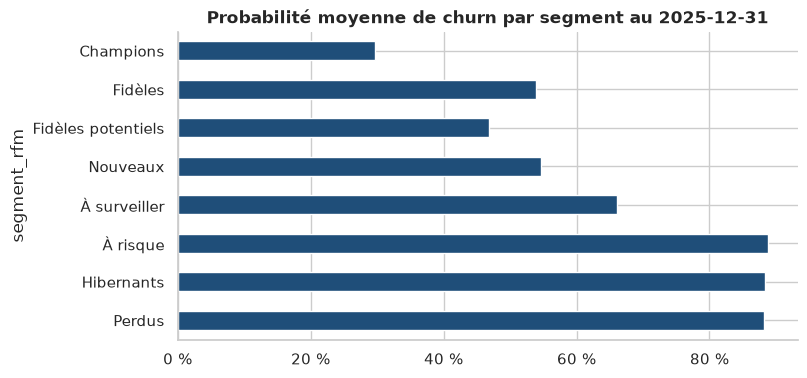

5 950 clients en alerte sur 7 377 (80.7%)


,clients,proba_moyenne,en_alerte,montant_ttc,part_en_alerte
segment_rfm,,,,,
Champions,1698,0.297,402,5 450 254.655,0.237
Fidèles,592,0.539,568,1 655 202.965,0.959
Fidèles potentiels,688,0.468,594,389 654.040,0.863
Nouveaux,539,0.546,529,104 925.700,0.981
À surveiller,728,0.662,725,214 283.625,0.996
À risque,1270,0.888,1270,2 862 809.790,1.000
Hibernants,931,0.884,931,433 510.600,1.000
Perdus,931,0.883,931,169 489.790,1.000


In [5]:
# Où sont les clients à risque ? (synthèse pour le marketing)
synthese_churn = scores.groupby("segment_rfm").agg(clients=("client_sk", "size"), proba_moyenne=("proba_churn", "mean"),
                                                  en_alerte=("alerte_churn", "sum"), montant_ttc=("montant_reconnu_ttc", "sum"))
synthese_churn["part_en_alerte"] = synthese_churn["en_alerte"] / synthese_churn["clients"]
synthese_churn = synthese_churn.reindex([s for s in features.ORDRE_SEGMENTS if s in synthese_churn.index])
cfg.exporter_table(synthese_churn, "ML08_churn_par_segment")
ax = synthese_churn["proba_moyenne"].plot.barh(color=cfg.BLEU, figsize=(8, 4))
ax.invert_yaxis(); ax.set_title(f"Probabilité moyenne de churn par segment au {DATE_SCORING.date()}"); cfg.format_pourcent(ax, "x")
montrer("ML08_1_churn_actuel")
print(f"{scores['alerte_churn'].sum():,} clients en alerte sur {len(scores):,} ({scores['alerte_churn'].mean():.1%})".replace(",", " "))
synthese_churn

**Lecture pour l'action.** Les clients en alerte des segments **Champions, Fidèles et Fidèles potentiels** sont ceux qui ont le plus de valeur à protéger ; dans les segments À risque, Hibernants et Perdus, la plupart des clients sont déjà partis. Comme dans `03_Prediction_Churn`, les **déciles 4 à 7** sont la cible la plus rentable.

## 3. Retard de livraison : modèle de production et colis en transit

Même pipeline (mêmes réglages) que le modèle retenu dans `06_Prediction_Retard_Livraison`, réappris sur les expéditions livrées des **12 derniers mois** (version 1.5 ; `temporal_split.FENETRE_RETARD_PRODUCTION_MOIS`).

*Pourquoi 12 mois et non tout l'historique ?* Rejoué mois par mois sur 2025 (`09_Suivi_Modeles`, section 4 bis), le modèle réappris chaque mois sur 12 mois donne 7 alertes de calibrage sur 48 (transporteur × mois) contre 14 pour tout l'historique, et aucune au 2nd semestre 2025 : il cesse de sous-estimer SahelLog dès que la rupture de juillet 2024 sort de la fenêtre. Les résultats évalués sur 2025 (`06`, `05`) ne changent pas : c'est une décision de production.

*Seuil d'alerte (version 1.5.1).* Le seuil 0,13 avait été choisi pour le modèle évalué. Le modèle de production est mieux calibré : à 0,13, il met en alerte plus d'un colis sur trois. Le seuil est donc choisi **à chaque exécution**, par la même règle que dans `06` (F1 maximal), sur la production **rejouée** des 12 derniers mois : chaque mois y est prédit par un modèle appris sur les 12 mois d'avant, donc sur des colis qu'il n'a pas vus. Sur les données au 31/12/2025 : **0,22** (précision 46 %, rappel 61 %, 23 % des colis en alerte, contre 37 %, 77 % et 36 % à 0,13).

Puis on score les colis **partis mais pas encore livrés** (statut `en_transit`).

In [6]:
evalue = joblib.load(cfg.DOSSIER_MODELES / "retard_modele.joblib")
retard = features.lire("ml_retard")
X_RET, SEUIL_EVALUE = evalue["variables"], evalue["seuil"]
# Version 1.5 : fenêtre de production choisie sur le suivi (09_Suivi_Modeles), indépendante de la fenêtre évaluée en 06
MOIS_PROD = temporal_split.FENETRE_RETARD_PRODUCTION_MOIS
FENETRE_PROD = f"{MOIS_PROD} derniers mois"
donnees = retard[retard["date_expedition"] > retard["date_expedition"].max() - pd.DateOffset(months=MOIS_PROD)]
pipe_ret = clone(evalue["pipeline"]).fit(donnees[X_RET], donnees["en_retard"])

# Version 1.5.1 : seuil d'alerte choisi sur la production rejouée des 12 derniers mois (même règle que 06 : F1 maximal)
rejeu_ret = outils_suivi.predictions_glissantes(retard, evalue["pipeline"], X_RET, "en_retard", "date_expedition",
                                                mois_fenetre=MOIS_PROD, nb_mois=12)
SEUIL_RET = round(validation.meilleur_seuil(rejeu_ret["en_retard"], rejeu_ret["proba"]), 2)
from sklearn.metrics import f1_score, precision_score, recall_score
comparaison_seuil = pd.DataFrame({
    f"{s:.2f}".replace(".", ","): {"F1": f1_score(rejeu_ret["en_retard"], rejeu_ret["proba"] >= s),
                                   "précision": precision_score(rejeu_ret["en_retard"], rejeu_ret["proba"] >= s),
                                   "rappel": recall_score(rejeu_ret["en_retard"], rejeu_ret["proba"] >= s),
                                   "part de colis en alerte": (rejeu_ret["proba"] >= s).mean()}
    for s in (SEUIL_EVALUE, SEUIL_RET)})
print(f"Seuil du modèle évalué : {SEUIL_EVALUE:.2f} ; seuil de production (F1 maximal sur {rejeu_ret['mois_rejoue'].nunique()} "
      f"mois rejoués, {len(rejeu_ret)} expéditions) : {SEUIL_RET:.2f}")
display(comparaison_seuil.round(3))

metriques = pd.read_csv(cfg.DOSSIER_TABLES / "ML_metriques_retard.csv", sep=";", decimal=",")
retenu = metriques[metriques["retenu"] == True].iloc[0]
f_ret = modeles.fiche("retard_production", "retard", objet=pipe_ret, donnees=donnees[X_RET + ["en_retard"]], cible="en_retard",
                      periode=f"expéditions du {donnees['date_expedition'].min().date()} au {donnees['date_expedition'].max().date()} ({FENETRE_PROD})",
                      variables=X_RET, seuil=SEUIL_RET, mesures={"AUC_test_2025": retenu["AUC"], "capture_top_20_test_2025": retenu["capture_top_20"],
                               "F1_production_rejouee": f1_score(rejeu_ret["en_retard"], rejeu_ret["proba"] >= SEUIL_RET),
                               "seuil_modele_evalue": SEUIL_EVALUE},
                      notes=f"modèle évalué : {retenu['modele']} ; production : réappris chaque mois sur les {FENETRE_PROD} (v1.5) ; "
                            f"seuil {SEUIL_RET:.2f} choisi sur la production rejouée (F1 maximal, v1.5.1)")
modeles.enregistrer({"pipeline": pipe_ret, "seuil": SEUIL_RET, "variables": X_RET, "fenetre": FENETRE_PROD}, f_ret)

en_cours = features.table_expeditions(p, vues, en_cours=True)
colis = en_cours[["livraison_id", "commande_id", "date_expedition", "transporteur", "region", "zone_livraison", "entrepot"]].copy()
colis["proba_retard"] = pipe_ret.predict_proba(en_cours[X_RET])[:, 1] if len(en_cours) else []
colis["alerte_retard"] = (colis["proba_retard"] >= SEUIL_RET).astype(int)
colis["date_scoring"] = DATE_SCORING
colis["version_modele"] = f_ret["version"]

# 🔗 Contrôle SQL direct : colis en transit
n_sql = chargement.valeur("SELECT COUNT(*) FROM bi.v_fact_livraisons WHERE statut_livraison = 'en_transit' AND date_expedition_sk > 0")
print(f"Colis en transit — SQL : {int(n_sql)} ; scorés : {len(colis)} ;", "OK" if int(n_sql) == len(colis) else "ÉCART")
cfg.exporter_resultat(colis, cfg.DOSSIER_PREDICTIONS / "retard_scores_en_cours.parquet")
par_transp = colis.groupby("transporteur").agg(colis=("livraison_id", "size"), proba_moyenne=("proba_retard", "mean"),
                                              en_alerte=("alerte_retard", "sum")).sort_values("proba_moyenne", ascending=False)
cfg.exporter_table(par_transp, "ML08_retard_en_cours")
par_transp

Seuil du modèle évalué : 0.13 ; seuil de production (F1 maximal sur 12 mois rejoués, 26590 expéditions) : 0.22


,"0,13","0,22"
F1,0.503,0.524
précision,0.374,0.458
rappel,0.770,0.613
part de colis en alerte,0.357,0.232


  fiche retard_production            version 2026.11.20.1403  (production)
Colis en transit — SQL : 211 ; scorés : 211 ; OK
  ✔ ana.ml_scores_retard_en_cours                   211 lignes
  ✔ ana.ml08_retard_en_cours                          4 lignes


,colis,proba_moyenne,en_alerte
transporteur,,,
SahelLog,82,0.550,82
Poste Colis Plus,70,0.281,42
Rapid Colis,38,0.083,0
TunExpress,21,0.072,0


**Rappel (06_Prediction_Retard_Livraison).** Le modèle évalué (appris sur 2023-2024) **sous-estime le niveau de retard de SahelLog** (17 % prévu pour 37 % réel en 2025). Le modèle de production, réappris sur les 12 derniers mois (version 1.5), ne contient plus la période d'avant la rupture : son calibrage par transporteur est suivi chaque mois dans `09_Suivi_Modeles` (section 4 bis).

## 3 bis. Demande : prévision par produit pour l'année suivante

Le modèle retenu est lu dans `ML_metriques_demande` (écrit par `04_Prediction_Demande`) : **version 3** (v2 corrigée de son biais, v1.6) si elle a rempli la règle, sinon **version 2**.
Aucune n'a de paramètre appris : la v2 se recalcule avec `features.prevision_demande_v2` à partir de l'année précédente, la v3 la multiplie par le coefficient de chaque catégorie appris sur la dernière année complète (`features.prevision_demande_v3`).
La v2 est toujours gardée dans la colonne `quantite_plancher`.

On l'applique ici aux **12 mois qui suivent les dernières données** (2026 si le DWH s'arrête en 2025).
On ajoute le stock de départ (fin décembre) pour repérer les produits qui tomberaient
en rupture **sans réapprovisionnement**.

| Sortie | Pour qui | Table dans TuniShop_ANALYTICS |
|---|---|---|
| Quantité prévue de chaque produit, chaque mois de l'année suivante, avec stock de départ et alerte de rupture | achats, approvisionnement | `ana.ml_scores_demande` |
"""


In [ ]:
produits_mois = features.lire("produits_mois")
ANNEE_PREV = DATE_SCORING.year + 1                      # 2026 si les données s'arrêtent en 2025
prec = produits_mois[produits_mois["mois"].dt.year == ANNEE_PREV - 1]
assert prec["mois"].nunique() == 12, f"L'année {ANNEE_PREV - 1} n'est pas complète : la version 2 a besoin de 12 mois."

# Grille : chaque produit vendu l'année précédente x les 12 mois à prévoir
produits = prec.drop_duplicates("produit_id")[["produit_id", "categorie"]]
mois_prev = pd.DataFrame({"mois": pd.date_range(f"{ANNEE_PREV}-01-01", periods=12, freq="MS")})
demande_prev = produits.merge(mois_prev, how="cross")
# Seule autre colonne utilisée par la version 2 (cas d'un produit sans part calculable)
demande_prev["moy_categorie_annee_prec"] = demande_prev["categorie"].map(prec.groupby("categorie")["quantite"].mean())
met_dem = pd.read_csv(cfg.DOSSIER_TABLES / "ML_metriques_demande.csv", sep=";", decimal=",")
MODELE_DEMANDE = met_dem.loc[met_dem["retenu"] == True, "modele"].iloc[0]
V3_RETENUE = MODELE_DEMANDE.endswith("(v3)")
demande_prev["quantite_plancher"] = features.prevision_demande_v2(demande_prev, produits_mois).round(1)   # v2, toujours gardée
demande_prev["quantite_prevue"] = (features.prevision_demande_v3(demande_prev, produits_mois).round(1) if V3_RETENUE
                                   else demande_prev["quantite_plancher"])
print(f"Modèle de demande retenu (04) : {MODELE_DEMANDE}")

# Stock de départ = stock de fin décembre de l'année précédente (tous entrepôts)
stock_depart = prec[prec["mois"] == prec["mois"].max()].set_index("produit_id")["stock_fin_mois"]
demande_prev["stock_depart"] = demande_prev["produit_id"].map(stock_depart)
demande_prev = demande_prev.sort_values(["produit_id", "mois"]).reset_index(drop=True)
demande_prev["demande_cumulee"] = demande_prev.groupby("produit_id")["quantite_prevue"].cumsum()
demande_prev["rupture_sans_reappro"] = (demande_prev["demande_cumulee"] > demande_prev["stock_depart"]).astype(int)
demande_prev["date_scoring"] = DATE_SCORING
demande_prev["version_modele"] = "demande_v3" if V3_RETENUE else "demande_v2"
demande_prev = demande_prev.drop(columns="moy_categorie_annee_prec")

# 🔗 Contrôles
n_vides = int(demande_prev["quantite_prevue"].isna().sum())
q_prec, q_prev = prec["quantite"].sum(), demande_prev["quantite_prevue"].sum()
print(f"{demande_prev['produit_id'].nunique()} produits x 12 mois = {len(demande_prev):,} lignes ; prévisions vides : {n_vides}".replace(",", " "))
print(f"Quantité {ANNEE_PREV - 1} réelle : {q_prec:,.0f} ; {ANNEE_PREV} prévue : {q_prev:,.0f} ({q_prev / q_prec - 1:+.1%})".replace(",", " "))
print(f"Plancher (v2) : {demande_prev['quantite_plancher'].sum():,.0f}".replace(",", " ")
      + (" ; prévision corrigée (v3) retenue" if V3_RETENUE else " ; v2 retenue : lire la prévision comme un plancher"))

cfg.exporter_resultat(demande_prev, cfg.DOSSIER_PREDICTIONS / "demande_scores_annee_suivante.parquet")

# Synthèse : premier mois de rupture prévu par produit (sans réapprovisionnement)
premiere_rupture = (demande_prev[demande_prev["rupture_sans_reappro"] == 1]
                    .groupby("produit_id")["mois"].min().dt.strftime("%Y-%m").value_counts().sort_index())
premiere_rupture.to_frame("produits dont le stock de départ est épuisé ce mois-là")

## 4. Registre des modèles

Les modèles de production ci-dessus et les autres modèles de la phase reçoivent leur fiche d'identité, publiée dans `ana.ml_registre_modeles`.

In [ ]:
def mesure(table, colonne):
    m = pd.read_csv(cfg.DOSSIER_TABLES / f"{table}.csv", sep=";", decimal=",")
    return float(m.loc[m["retenu"] == True, colonne].iloc[0])

ventes = features.lire("ml_ventes")
ridge = joblib.load(cfg.DOSSIER_MODELES / "prevision_ventes_ridge_2023_2025.joblib")
modeles.enregistrer(None, modeles.fiche("prevision_ventes_ridge_2023_2025", "ventes", donnees=ventes, cible="ca_ttc",
    periode="mois de 2023 à 2025", variables=features.colonnes_ml("ventes"), reglages=str(ridge)[:300],
    mesures={"MAPE_test_2025": mesure("ML_metriques_ventes", "MAPE_total")},
    notes="Ridge « calendrier » réappris sur 2023-2025 par 02_Prevision_Ventes ; sert à la prévision 2026"))
if V3_RETENUE:
    modeles.enregistrer(None, modeles.fiche("demande_v3", "demande", periode="coefficient par catégorie appris sur la dernière année complète",
        variables=["categorie", "mois", "part du produit", "coefficient réel / prévu de l'année précédente"], reglages="features.prevision_demande_v3",
        mesures={"WAPE_test_2025": mesure("ML_metriques_demande", "WAPE_produit_mois")},
        notes="v2 corrigée de son biais (v1.6) ; retenue sur 2025 (biais plus proche de 0, WAPE pas plus mauvaise)"))
modeles.enregistrer(None, modeles.fiche("demande_v2", "demande", periode="année précédente (aucun paramètre appris)",
    variables=["categorie", "mois", "part du produit"], reglages="features.prevision_demande_v2",
    mesures={"WAPE_test_2025": float(met_dem.loc[met_dem["modele"] == "Catégorie × part produit (v2)", "WAPE_produit_mois"].iloc[0])},
    notes=("plancher (v1.6) ; " if V3_RETENUE else "") + "retenue sur la validation 2024 (règle : au moins 1 % de mieux que la référence)"))
km_fiche = modeles.fiche("clustering_kmeans", "segmentation", periode=f"photo du {km['date_reference']}",
    variables=list(km["variables"]), reglages=f"KMeans(n_clusters={km['kmeans'].n_clusters})",
    notes="groupes : " + ", ".join(km["noms"].values()))
modeles.enregistrer(None, km_fiche)
modeles.enregistrer(None, modeles.fiche("rfm_seuils", "segmentation", periode="photos d'apprentissage 2023-2024",
    variables=["recence_j", "frequence", "montant_reconnu_ttc"], reglages=json.dumps(seuils)[:300], notes="seuils des scores R, F, M"))
registre = modeles.publier_registre()
registre[["nom", "cas", "role", "version", "periode_apprentissage", "lignes_apprentissage"]]

In [9]:
chargement.fermer_connexion()

Connexion fermée.
